In [1]:
from anomalib.data import MVTecAD
from anomalib.models import Patchcore
from anomalib.engine import Engine
from pathlib import Path
from lightning.pytorch.callbacks import TQDMProgressBar
import matplotlib.pyplot as plt
import torch

W1031 11:15:08.959000 24072 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels
c:\Users\flavi\.python-envs\anomaly_det\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
c:\Users\flavi\.python-envs\anomaly_det\Lib\site-packages\anomalib\models\image\dinomaly\components\layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


In [2]:
# dataset configuration 
ROOT_DIR = Path("./data/MVTec").resolve()

datamodule = MVTecAD(
    root=ROOT_DIR, # Load the MVTec dataset from this path (e.g., ./data/MVTec)
    category="wood", # automatically use wood/train and wood/test
    train_batch_size=32,
    eval_batch_size=32,
    num_workers=0,
)


# check which folder is being used for training, validation, and testing
# debugging purposes only, to be removed
datamodule.setup()
print("TRAIN:")
for batch in datamodule.train_dataloader():
    print(batch["image_path"][:3])
    break

print("\nVALIDATION:")
for batch in datamodule.val_dataloader():
    print(batch["image_path"][:3])
    break

print("\nTEST:")
for batch in datamodule.test_dataloader():
    print(batch["image_path"][:3])
    break


# patchcore model configuration
model = Patchcore(
    backbone="resnet18",   # available backbones: "resnet18", "resnet50", "wide_resnet50_2"
    layers=["layer2", "layer3"],  # layers from which to extract features
    coreset_sampling_ratio=0.1,   # retain 10% of the patches to keep the memory bank compact and fast
)

# Execution Engine
engine = Engine(
    max_epochs=1,
    accelerator="auto",
    default_root_dir="./experiments/patchcore_wood",
    callbacks=[TQDMProgressBar()],  # Use tqdm instead of rich progress bar, rich progress bar is not compatible with Jupyter Notebook and causes errors when running in a notebook environment
    enable_model_summary=False,     # Disable model summary printing, rich progress bar tries to print the model summary 
)

# Memory Bank Extraction
engine.fit(model=model, datamodule=datamodule)

# Testing the model on the test set
test_results = engine.test(model=model, datamodule=datamodule)
print(test_results)

TRAIN:
['C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/train/good/114.png', 'C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/train/good/145.png', 'C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/train/good/034.png']

VALIDATION:
['C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/test/color/000.png', 'C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/test/color/001.png', 'C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/test/color/002.png']

TEST:
['C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/test/color/000.png', 'C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/test/color/001.png', 'C:\\Users\\flavi\\Documents\\ai_industry\\data\\MVTec\\wood/test/color/002.png']


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 5060 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\flavi\.python-envs\anomaly_det\Lib\site-packages\lightning\pytorch\core\optimizer.py:183: `LightningModule.configure_optimizers` returned `None`, this fit will run with no optimizer
c:\Users\flavi\.python-envs\anomaly_det\Lib\site-packages\lightning\pytorch\utilit

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]











































































































































































































































































































































































































































































































































































Selecting Coreset Indices.: 100%|██████████| 21503/21503 [00:56<00:00, 380.75it/s]
`Trainer.fit` stopped: `max_epochs=1` reached.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\flavi\.python-envs\anomaly_det\Lib\site-packages\lightning\pytorch\trainer\connecto

Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│        image_AUROC        │    0.9877192378044128     │
│       image_F1Score       │    0.9666666388511658     │
│        pixel_AUROC        │    0.9195170998573303     │
│       pixel_F1Score       │    0.43478426337242126    │
└───────────────────────────┴───────────────────────────┘

[{'image_AUROC': 0.9877192378044128, 'image_F1Score': 0.9666666388511658, 'pixel_AUROC': 0.9195170998573303, 'pixel_F1Score': 0.43478426337242126}]


ckpt_path is not provided. Model weights will not be loaded.
The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\flavi\.python-envs\anomaly_det\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9270114..1.9552122].


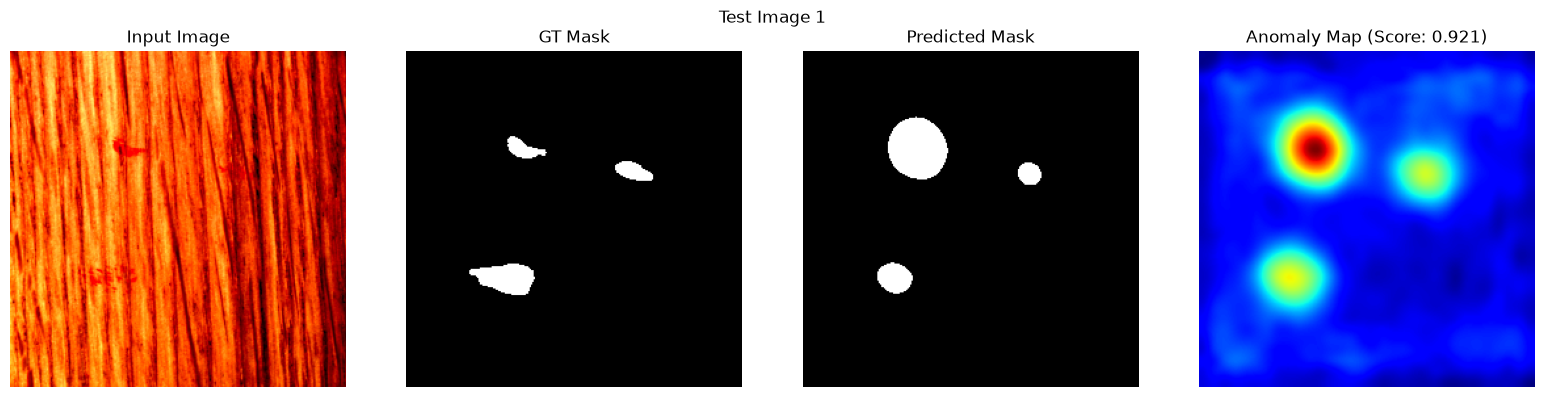

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2649274..1.8065917].


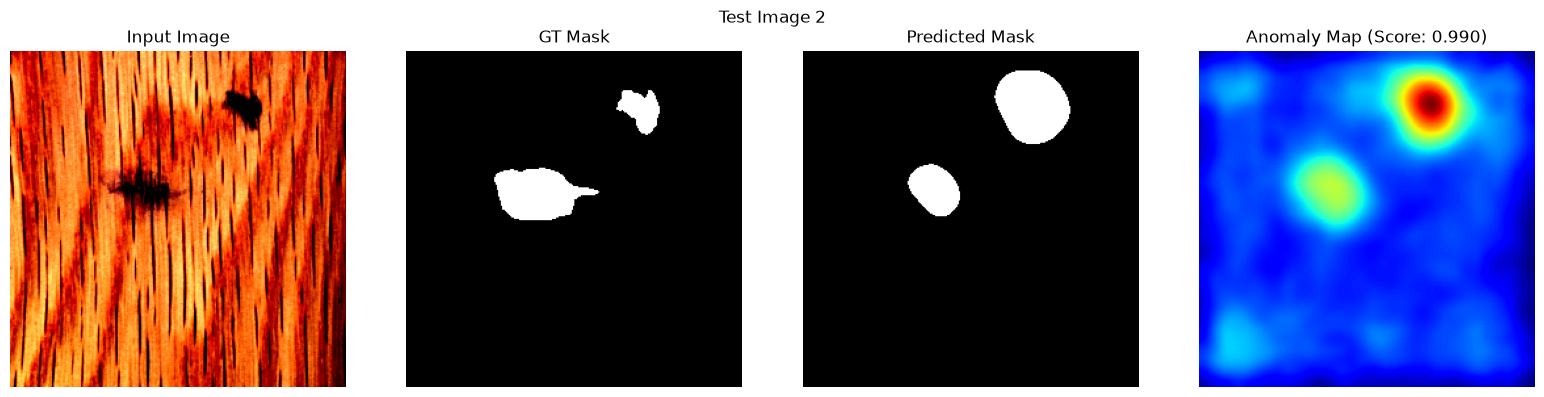

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1090568..1.7401998].


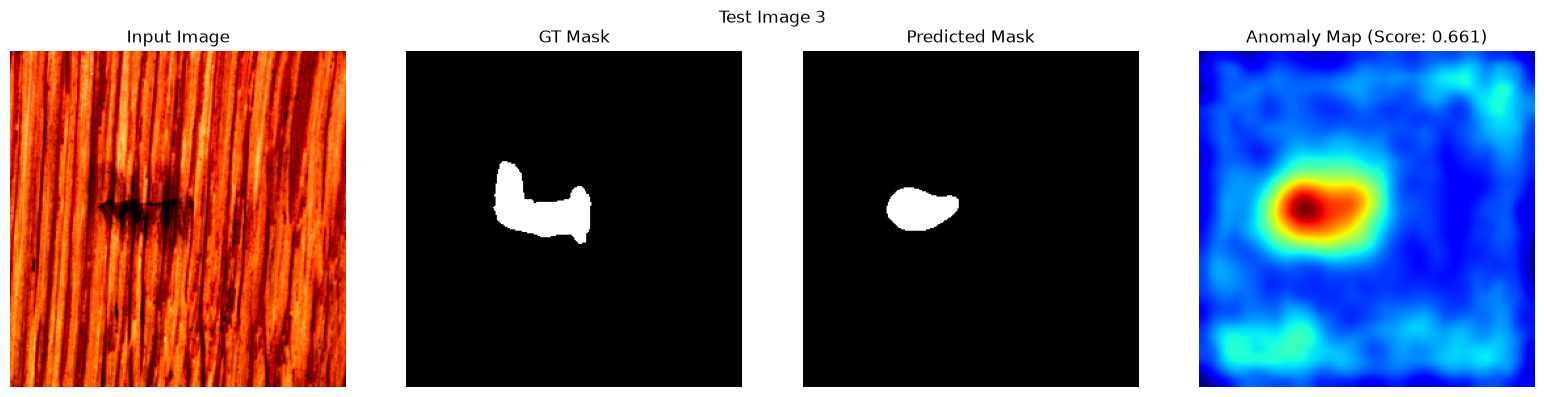

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8448445..1.4546813].


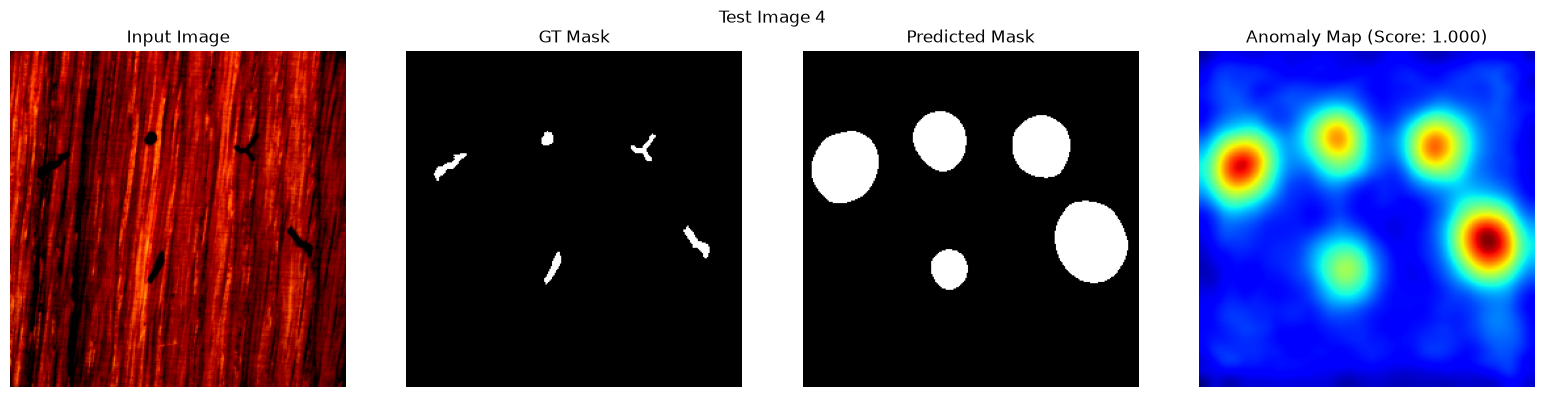

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0905925..1.8951755].


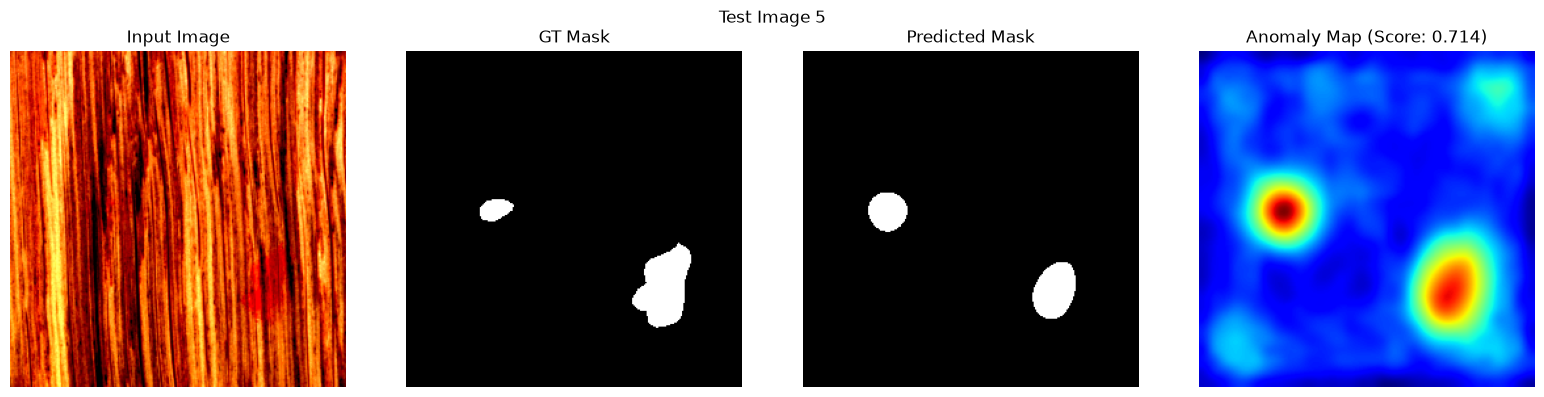

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.4412796..1.7501332].


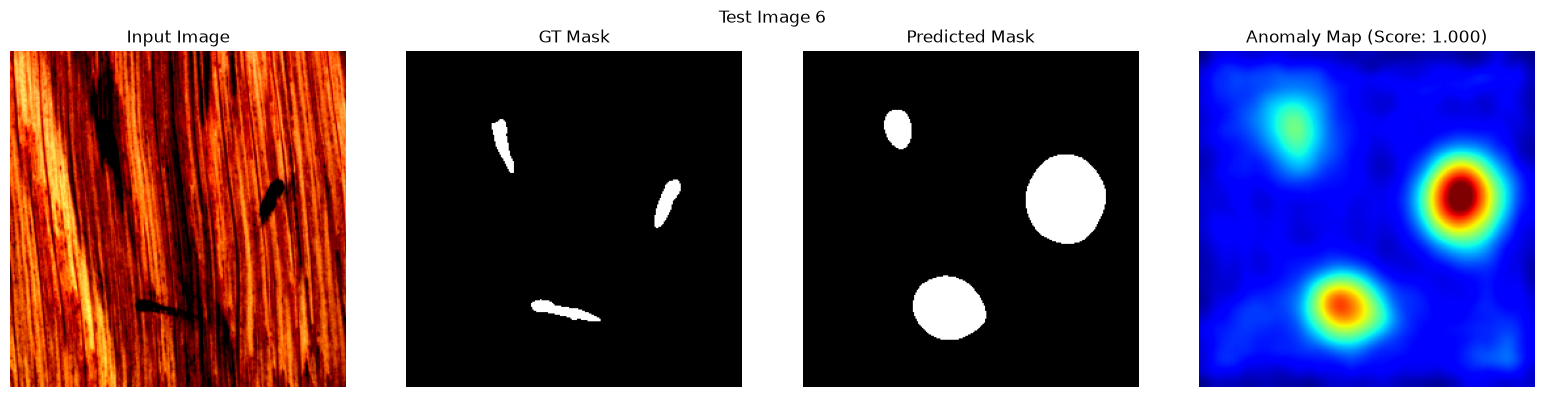

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0619556..1.6769186].


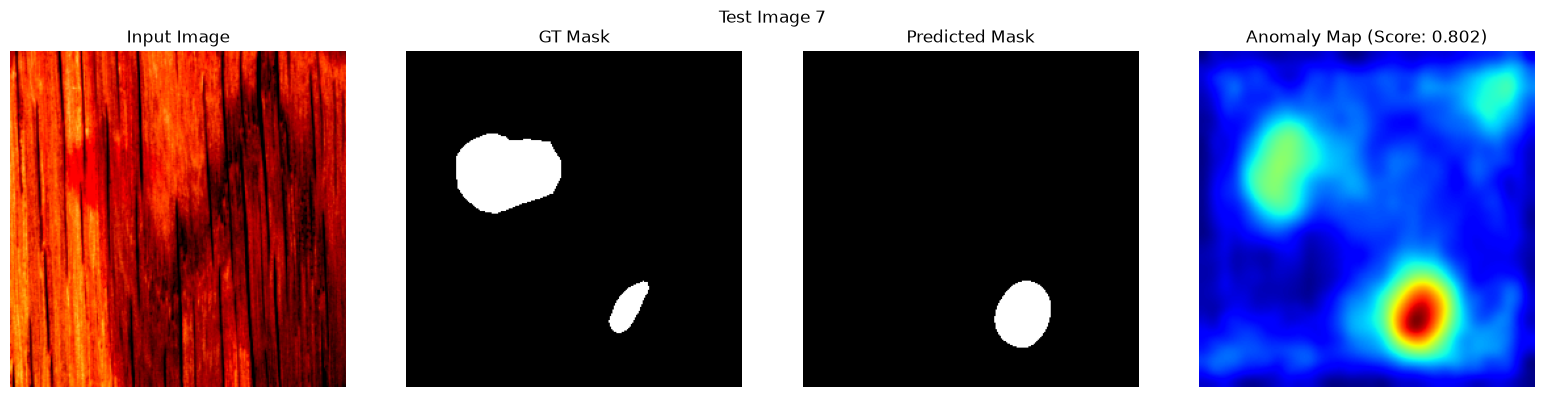

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.94698036..1.8393195].


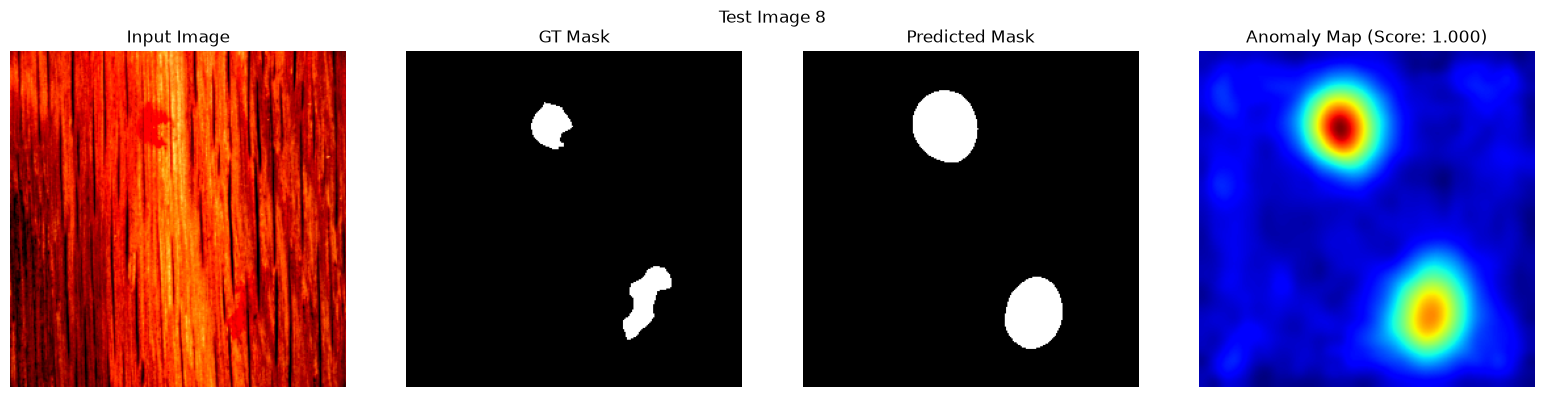

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8183737..2.2257295].


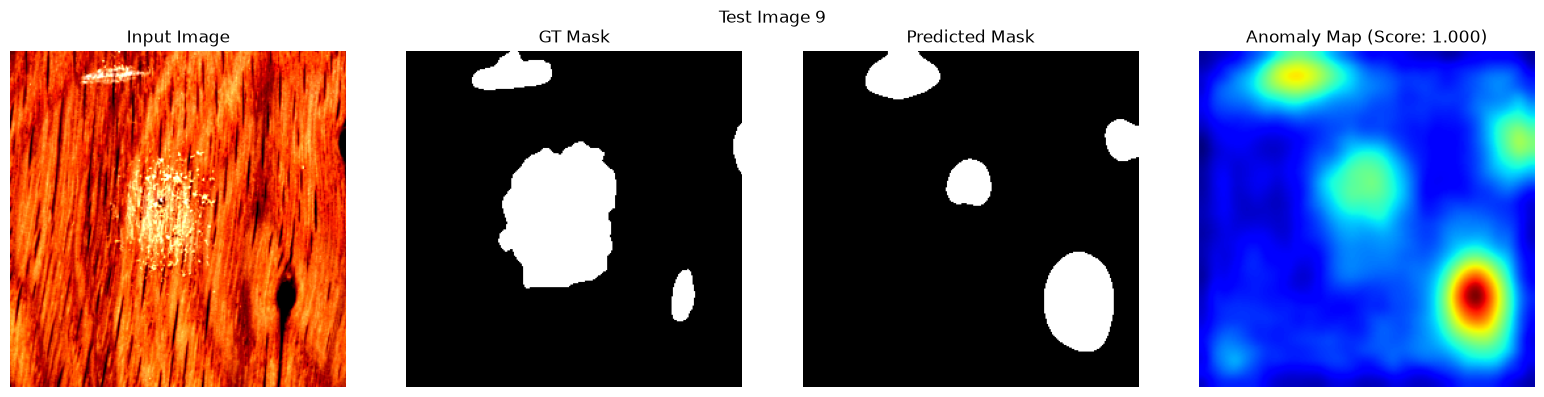

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.49192..2.2418678].


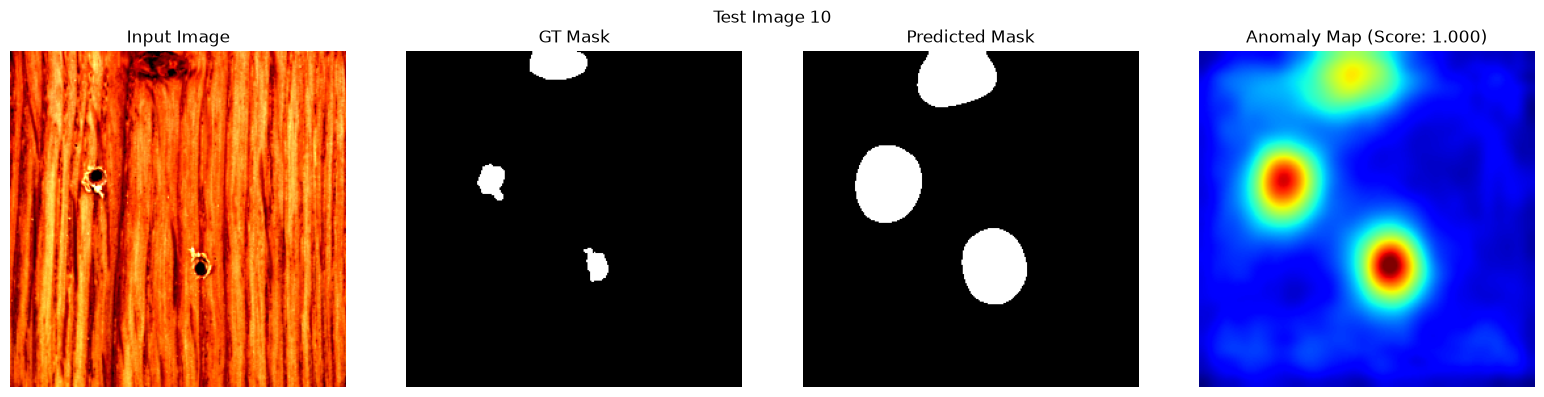

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2342046..2.0481439].


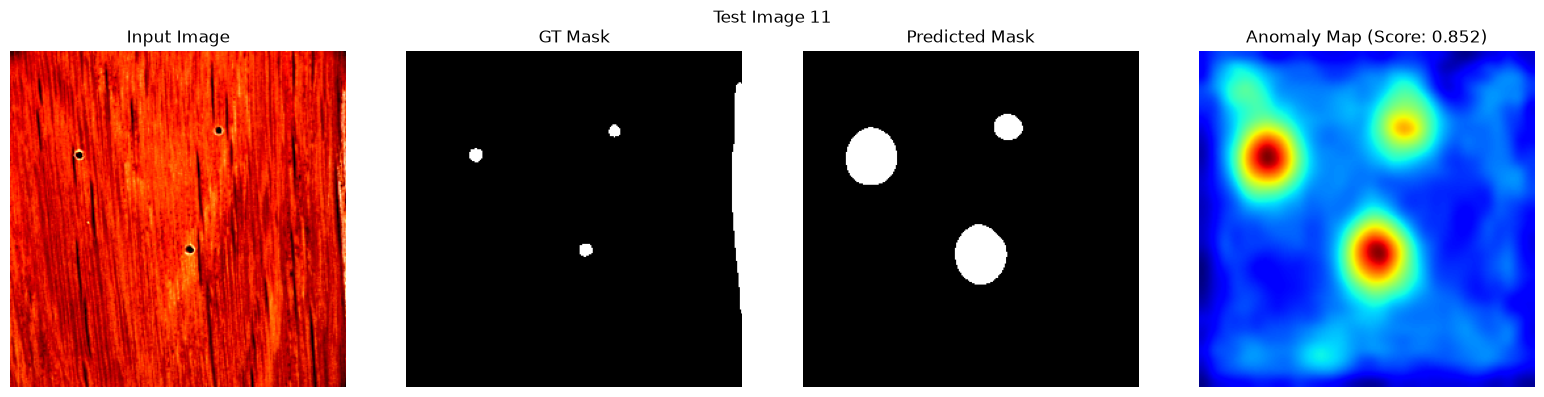

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.944014..2.200394].


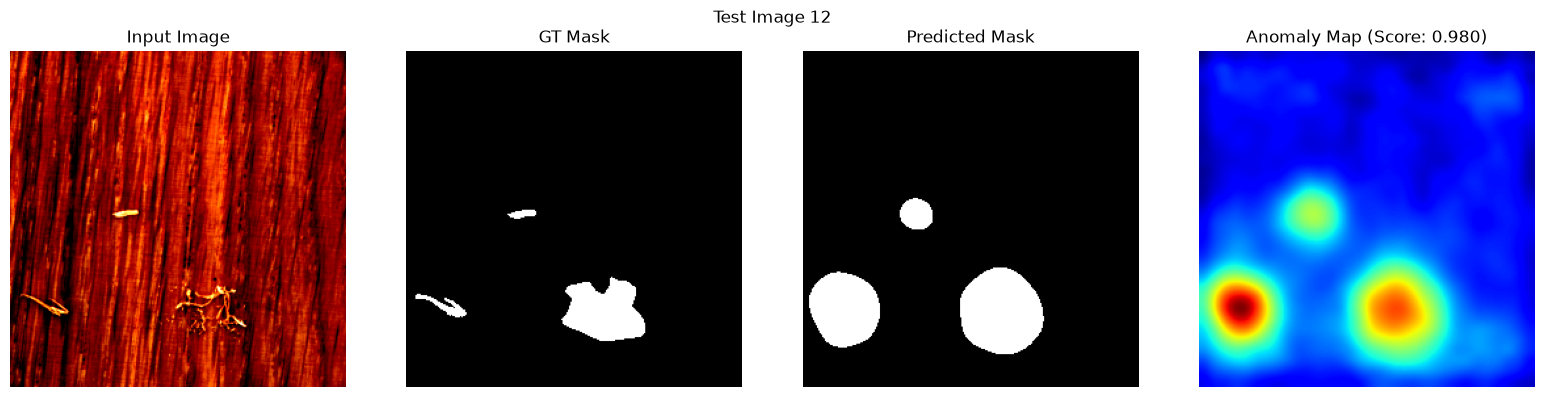

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8897635..1.6640081].


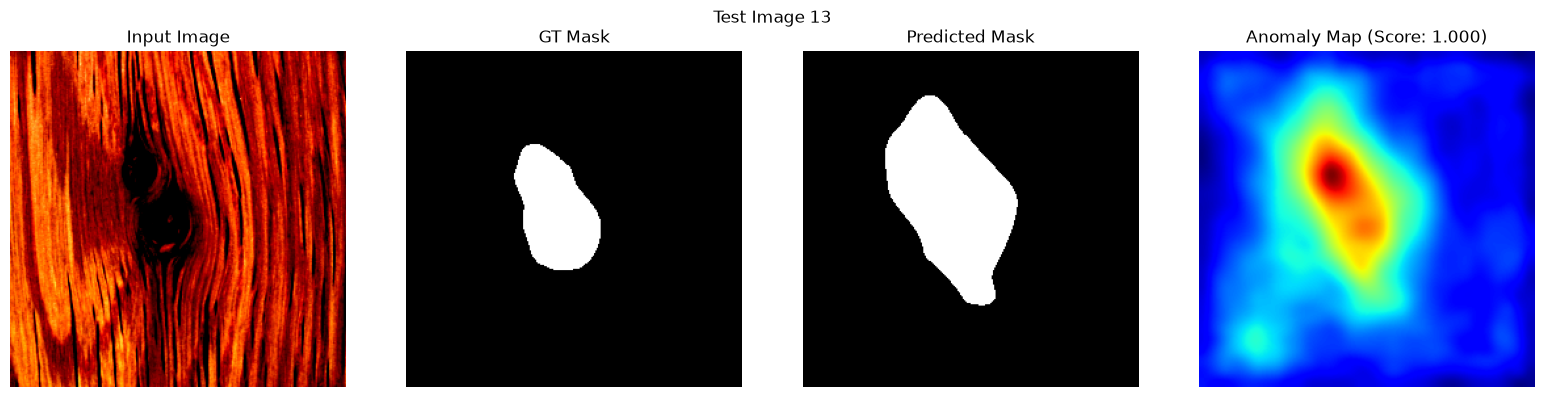

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1492342..1.5487337].


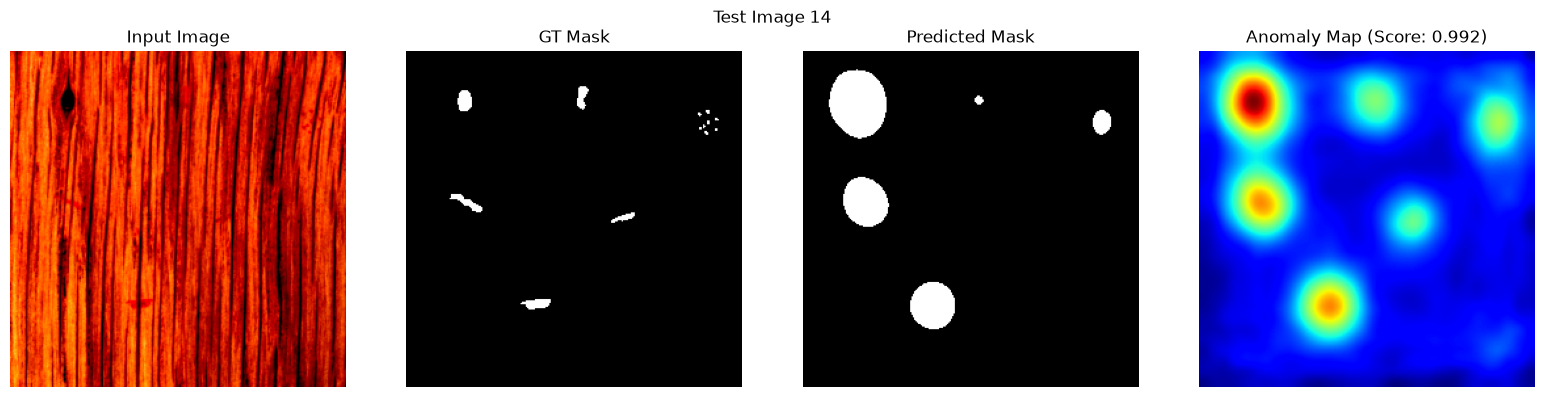

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8267497..1.7478255].


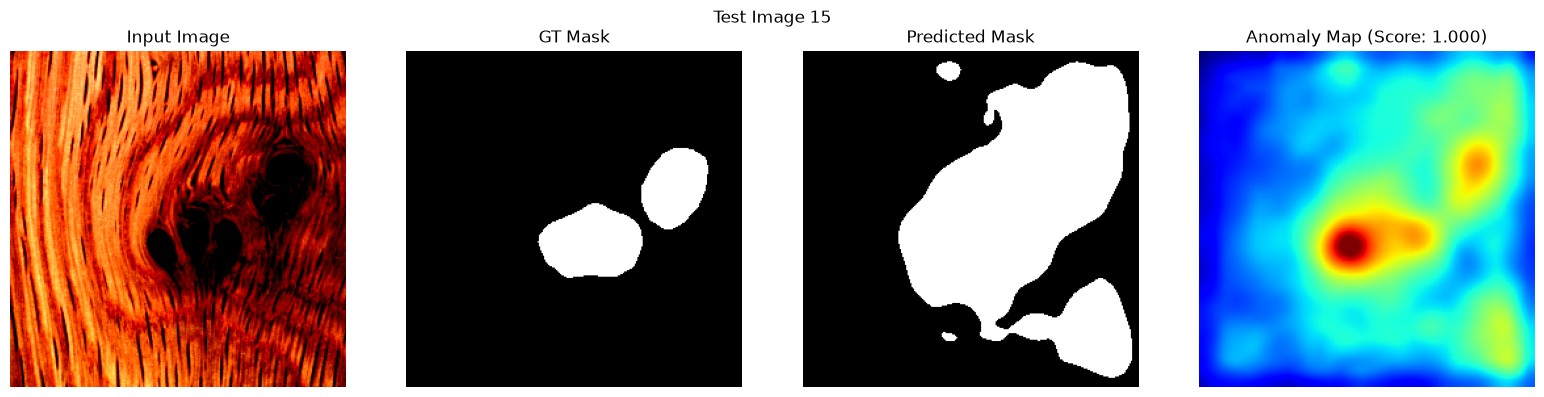

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8349274..2.044097].


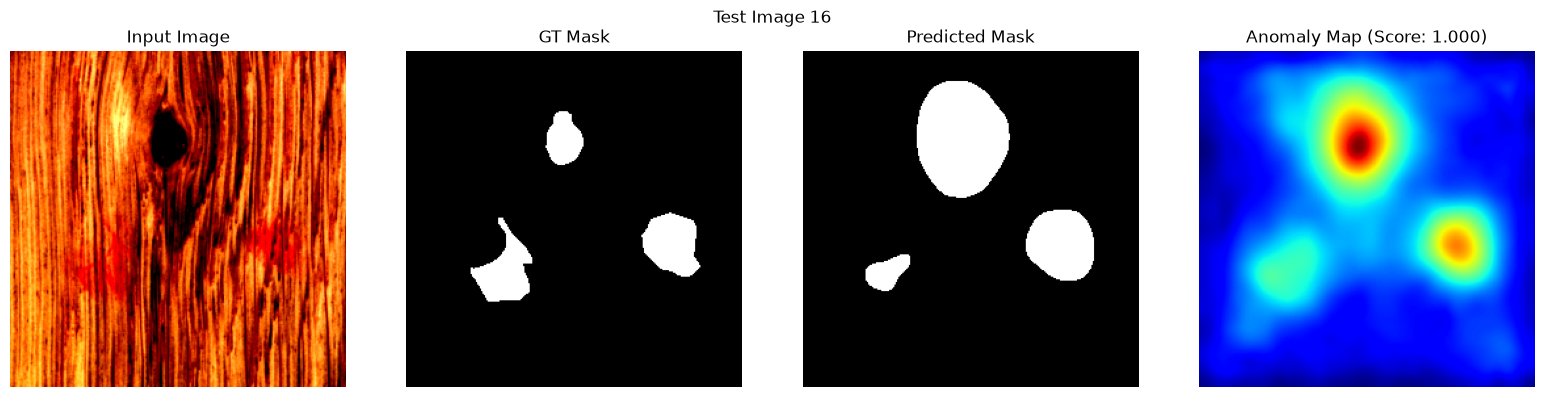

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7823825..1.7619734].


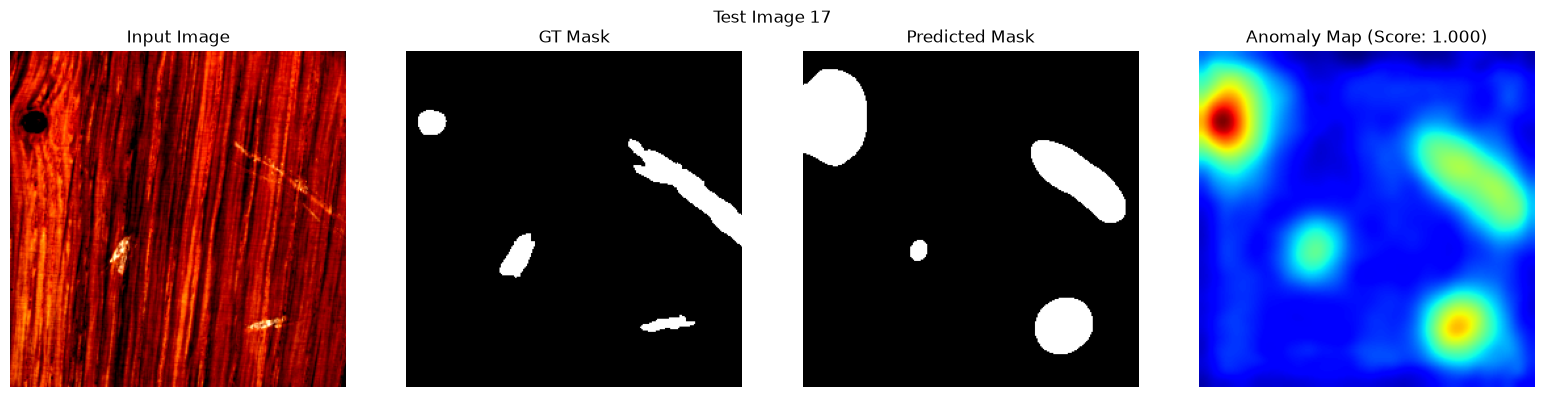

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.74626..1.9576706].


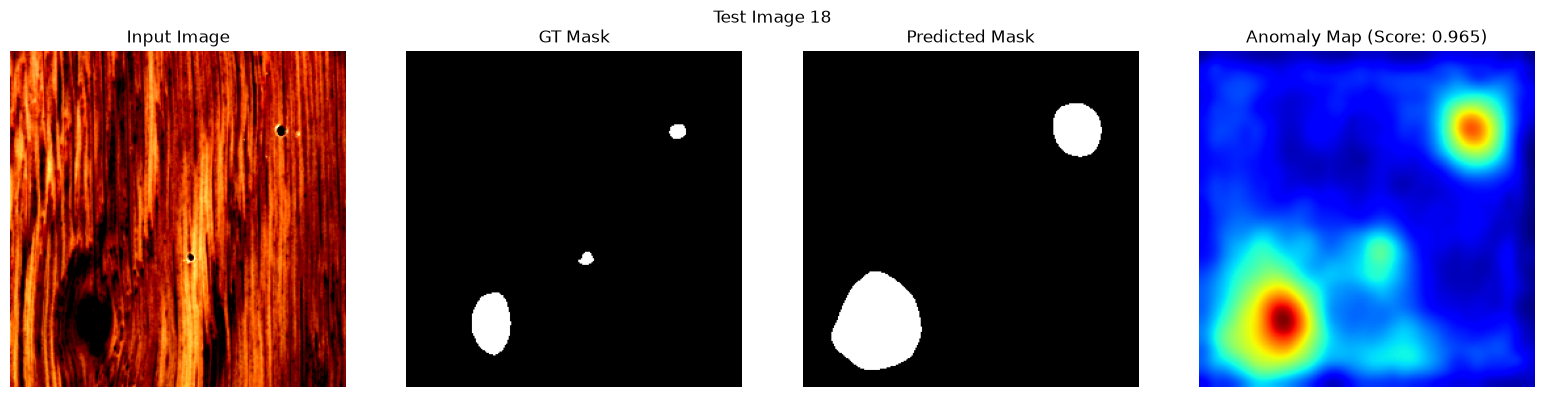

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.6742659..1.808163].


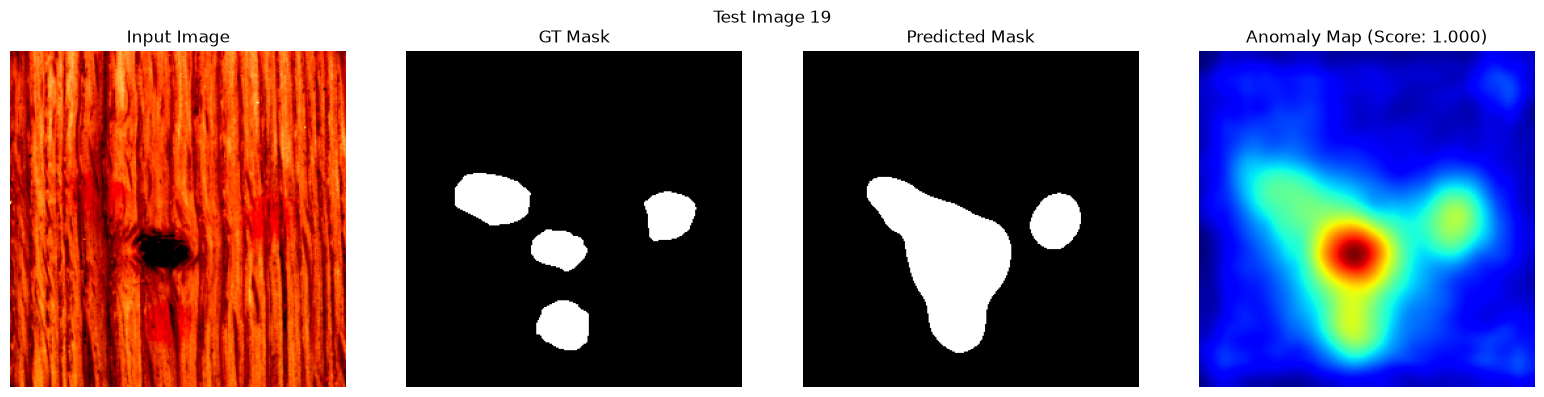

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.7896364..1.6361634].


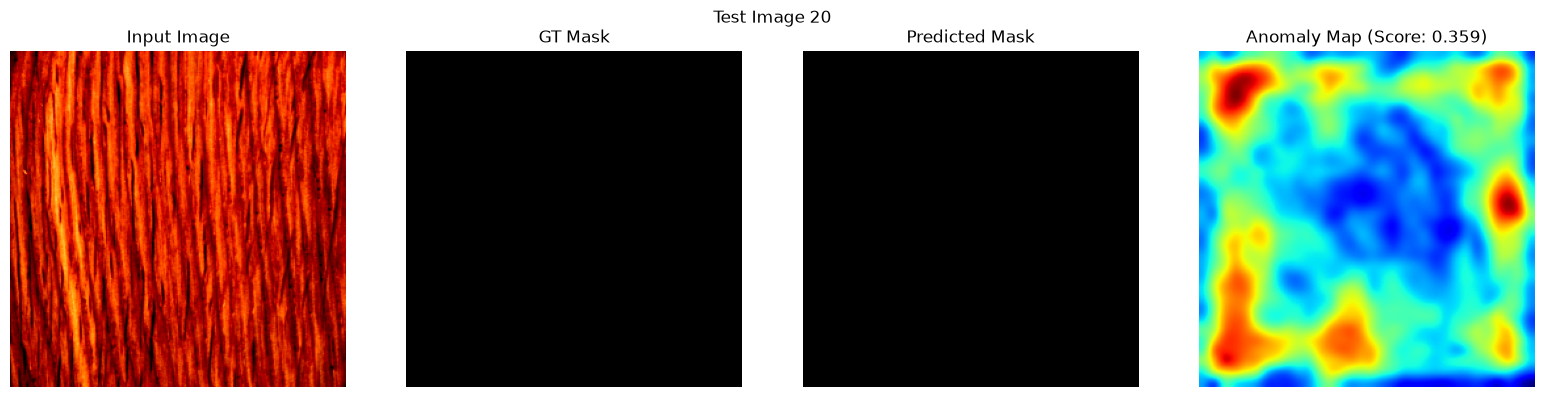

In [3]:
# visualize the predictions on the test set
predictions = engine.predict(model=model, datamodule=datamodule)

max_images = 20
count = 0

for batch in predictions:

    images = batch["image"]
    gt_masks = batch["gt_mask"]
    pred_masks = batch["pred_mask"]
    anomaly_maps = batch["anomaly_map"]
    scores = batch["pred_score"]

    batch_size = images.shape[0]

    for j in range(batch_size):

        if count >= max_images:
            break

        fig, axes = plt.subplots(1, 4, figsize=(16, 4))

        # Input image
        axes[0].imshow(
            images[j].permute(1, 2, 0).cpu().numpy()
        )
        axes[0].set_title("Input Image")

        # Ground Truth
        axes[1].imshow(
            gt_masks[j].squeeze().cpu().numpy(),
            cmap="gray"
        )
        axes[1].set_title("GT Mask")

        # Predicted Mask
        axes[2].imshow(
            pred_masks[j].squeeze().cpu().numpy(),
            cmap="gray"
        )
        axes[2].set_title("Predicted Mask")

        # Anomaly Map
        axes[3].imshow(
            anomaly_maps[j].squeeze().cpu().numpy(),
            cmap="jet"
        )
        axes[3].set_title(
            f"Anomaly Map (Score: {scores[j].item():.3f})"
        )

        for ax in axes:
            ax.axis("off")

        plt.suptitle(f"Test Image {count + 1}")
        plt.tight_layout()
        plt.show()

        count += 1

    if count >= max_images:
        break